### This file must be run once each season is over to determine if any feature changes must be made

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
import shap
from sklearn.metrics import mean_absolute_error
from scipy.stats import spearmanr

In [2]:
script_dir = Path.cwd()
repo_dir = script_dir.parent
train_dir = repo_dir/'data'/'train'

In [3]:
files = list(train_dir.glob('*.parquet'))

# dataframe concatenation
df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 4892 entries, 0 to 4891
Data columns (total 33 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Player            4892 non-null   str    
 1   Team              4892 non-null   str    
 2   G                 4892 non-null   float64
 3   MPG               4892 non-null   float64
 4   PTS               4892 non-null   float64
 5   AST               4892 non-null   float64
 6   TRB               4892 non-null   float64
 7   Stocks            4892 non-null   float64
 8   eFG%              4892 non-null   float64
 9   MP                4892 non-null   float64
 10  PER               4892 non-null   float64
 11  TS%               4892 non-null   float64
 12  USG%              4892 non-null   float64
 13  WS                4892 non-null   float64
 14  VORP              4892 non-null   float64
 15  Team_Win%         4892 non-null   float64
 16  Team_G            4892 non-null   float64
 17  pie   

In [222]:
check = df[df['Share'] == df.groupby('Year')['Share'].transform('max')]
failed_filter = check[
    (check['PTS'] < 10) |
    (check['Team_Win%'] < 0.42) |
    (check['PER'] < 20)
]

print(failed_filter[['Year', 'Player', 'PTS', 'Team_Win%', 'PER']])

Empty DataFrame
Columns: [Year, Player, PTS, Team_Win%, PER]
Index: []


In [5]:
df = df[(df['PTS'] > 10) & (df['Team_Win%'] > 0.420) & (df['PER'] > 20)]

In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 635 entries, 0 to 4861
Data columns (total 33 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Player            635 non-null    str    
 1   Team              635 non-null    str    
 2   G                 635 non-null    float64
 3   MPG               635 non-null    float64
 4   PTS               635 non-null    float64
 5   AST               635 non-null    float64
 6   TRB               635 non-null    float64
 7   Stocks            635 non-null    float64
 8   eFG%              635 non-null    float64
 9   MP                635 non-null    float64
 10  PER               635 non-null    float64
 11  TS%               635 non-null    float64
 12  USG%              635 non-null    float64
 13  WS                635 non-null    float64
 14  VORP              635 non-null    float64
 15  Team_Win%         635 non-null    float64
 16  Team_G            635 non-null    float64
 17  pie         

In [226]:
# initial model training
# based on resulting metrics (SHAP, spearmanr, MAE, plus corr matrix) try to figure out if PIE is necessary. If not, get 1980-1996 data and run this again

df_train = df[df['Year'] < 2026] #exclude testing data
val_seasons = range(1997,2026) #29 validation folds to average out metrics

all_features = ['Player', 'Team', 'G', 'MPG', 'PTS', 'AST', 'TRB', 'Stocks', 'eFG%','MP', 'PER', 'TS%', 'USG%', 'WS', 
                'VORP', 'Team_Win%', 'Team_G', 'pie','Year', 'Games_Played_PCT', 'z_PTS', 'z_AST', 'z_TRB', 'z_Stocks',
                'z_eFG%', 'z_MP', 'z_TS%', 'z_USG%', 'z_WS', 'z_VORP', 'z_Team_Win%','z_pie']


features = ['z_PTS','z_AST','z_TRB','z_Stocks','z_VORP','z_USG%','z_Team_Win%','z_eFG%','z_pie','PER']
target = ['Share']

scores = []
shap_values_list = []

for val_year in val_seasons:
    train_data = df_train[df_train['Year'] < val_year]
    val_data = df_train[df_train['Year'] == val_year]

    X_tr = train_data[features]
    y_tr = train_data[target]
    X_vl = val_data[features]
    y_vl = val_data[target]

    model = XGBRegressor(random_state = 23)
    model.fit(X_tr, y_tr)

    preds = model.predict(X_vl)
    mae = mean_absolute_error(y_vl, preds)
    spearman, _ = spearmanr(y_vl, preds)

    explainer = shap.TreeExplainer(model)
    shap_values = explainer(X_vl)
    
    fold_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=features)
    shap_values_list.append(fold_shap)

    val_data['predicted'] = preds
    # top_10_predicted = val_data.nlargest(10, 'predicted')['Player'].values
    # actual_winner    = val_data.loc[val_data[target].idxmax(), 'Player']
    # winner_in_top10  = 1 if actual_winner in top_10_predicted else 0

    scores.append({
        'year':            val_year,
        'mae':             mae,
        'spearman':        spearman
        # 'winner_in_top10': winner_in_top10,
        # 'actual_winner':   actual_winner
    })

    print(f"{val_year} → MAE: {mae:.3f} | Spearman: {spearman:.3f}")

/tmp/ipykernel_22942/267866759.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman, _ = spearmanr(y_vl, preds)


1997 → MAE: 0.145 | Spearman: nan
1998 → MAE: 0.131 | Spearman: 0.592
1999 → MAE: 0.280 | Spearman: 0.462
2000 → MAE: 0.129 | Spearman: 0.886
2001 → MAE: 0.108 | Spearman: 0.759
2002 → MAE: 0.066 | Spearman: 0.841
2003 → MAE: 0.106 | Spearman: 0.752
2004 → MAE: 0.110 | Spearman: 0.779
2005 → MAE: 0.186 | Spearman: 0.574
2006 → MAE: 0.121 | Spearman: 0.672
2007 → MAE: 0.070 | Spearman: 0.717
2008 → MAE: 0.125 | Spearman: 0.710
2009 → MAE: 0.089 | Spearman: 0.872
2010 → MAE: 0.075 | Spearman: 0.824
2011 → MAE: 0.084 | Spearman: 0.638
2012 → MAE: 0.038 | Spearman: 0.734
2013 → MAE: 0.085 | Spearman: 0.853
2014 → MAE: 0.111 | Spearman: 0.690
2015 → MAE: 0.036 | Spearman: 0.754
2016 → MAE: 0.083 | Spearman: 0.653
2017 → MAE: 0.077 | Spearman: 0.773
2018 → MAE: 0.047 | Spearman: 0.774
2019 → MAE: 0.035 | Spearman: 0.841
2020 → MAE: 0.064 | Spearman: 0.770
2021 → MAE: 0.041 | Spearman: 0.688
2022 → MAE: 0.052 | Spearman: 0.854
2023 → MAE: 0.057 | Spearman: 0.817
2024 → MAE: 0.060 | Spearman: 

In [227]:
scores_df = pd.DataFrame(scores)


── Cross Validation Summary ──────────────────────────
Average MAE:      0.091
Average Spearman: 0.741

Worst years by Spearman:
    year       mae  spearman
2   1999  0.280185  0.461538
8   2005  0.186416  0.574049
1   1998  0.130842  0.592013
14  2011  0.084305  0.637555
19  2016  0.083398  0.652837

── Averaged SHAP Feature Importance (across all folds) ──
z_VORP         0.068938
z_Team_Win%    0.041231
PER            0.039418
z_PTS          0.032426
z_pie          0.019598
z_AST          0.014766
z_USG%         0.012354
z_TRB          0.009978
z_eFG%         0.008495
z_Stocks       0.005281


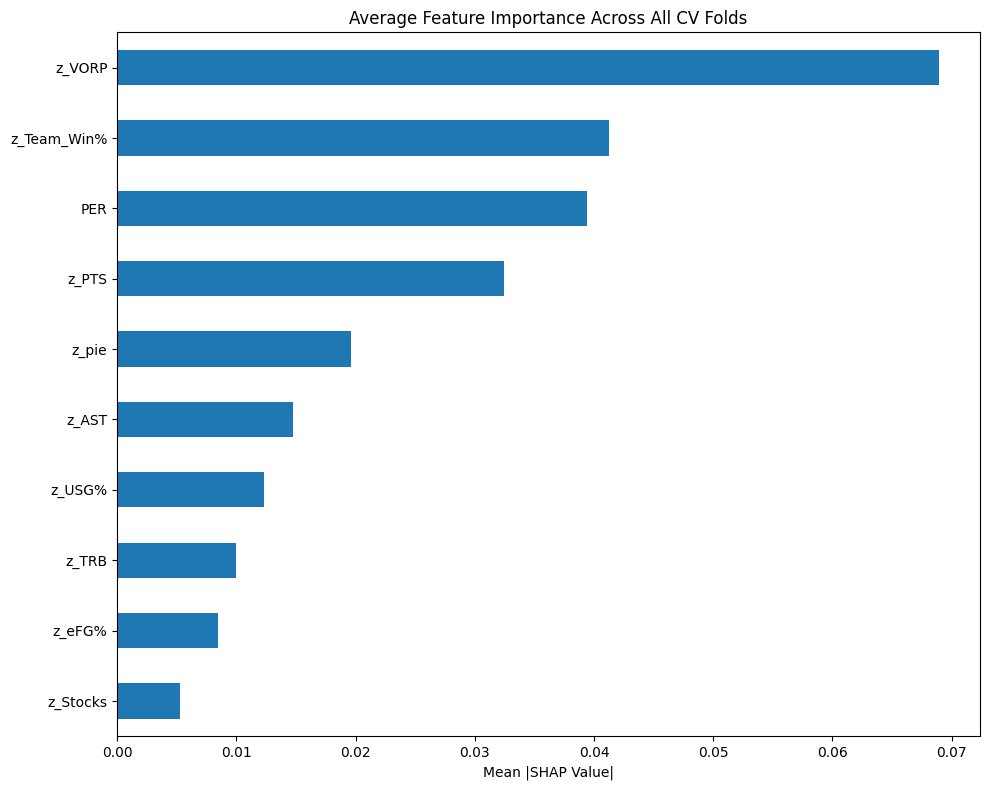

In [228]:
print(f"\n── Cross Validation Summary ──────────────────────────")
print(f"Average MAE:      {scores_df['mae'].mean():.3f}")
print(f"Average Spearman: {scores_df['spearman'].mean():.3f}")
# print(f"Winner in top 10: {scores_df['winner_in_top10'].sum()}/{len(scores_df)} seasons")
print(f"\nWorst years by Spearman:")
print(scores_df.nsmallest(5, 'spearman')[['year', 'mae', 'spearman']])

# ── Averaged SHAP Across All Folds ────────────────────────────────────────────
shap_df = pd.DataFrame(shap_values_list)

# Average importance across all folds
mean_shap = shap_df.mean().sort_values(ascending=False)

print(f"\n── Averaged SHAP Feature Importance (across all folds) ──")
print(mean_shap.to_string())

# Visualize
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
mean_shap.plot(kind='barh')
plt.xlabel('Mean |SHAP Value|')
plt.title('Average Feature Importance Across All CV Folds')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
